# =========================
# IMPORTAÇÃO DE BIBLIOTECAS, CONFIGURAÇÕES E DONWLOAD DA FONTE DOS DADOS
# =======================================================================

In [ ]:
# Bibliotecas (sugestões)
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Bibliotecas importadas com sucesso!')
print(f"Versão do Scikit-Learn: {sklearn.__version__}")

# Modelo de Machine Learning Arvore de Decisão
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Modelo de Machine LEarning KNN (K-Nearest Neighbors)
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.preprocessing import StandardScaler

print('Modelos de ML importados com sucesso!')

# Carregamentos dos dados brutos
df = pd.read_csv('C:\\Users\\miran\\OneDrive\\Desktop\\Curso_Integracao_IA_com_Dados\\Projeto_de_Machine_Learning_Isaac_Trenard\\data\\raw\\occupancy_completo.csv', sep=',', encoding='utf-8',parse_dates=['date'])
print(f'Dados carregados com sucesso! Shape: {df.shape}')

# Setting visuais dos nossos gráficos 
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme (style='whitegrid', palette='Set2')
print('Configurações visuais aplicadas com sucesso!')

Bibliotecas importadas com sucesso!
Versão do Scikit-Learn: 1.9.1
Modelos de ML importados com sucesso!
Dados carregados com sucesso! Shape: (20560, 7)
Configurações visuais aplicadas com sucesso!


# Sprint 1: Fase 1 - Análise Exploratória (EDA)

In [3]:
# Informações sobre o DataFrame (tipo de dados, número de colunas)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           20560 non-null  datetime64[us]
 1   Temperature    20560 non-null  float64       
 2   Humidity       20560 non-null  float64       
 3   Light          20560 non-null  float64       
 4   CO2            20560 non-null  float64       
 5   HumidityRatio  20560 non-null  float64       
 6   Occupancy      20560 non-null  int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 1.1 MB


In [4]:
# Primeiras linhas do DataFrame 
df.head(5)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [5]:
# Últimas linhas do DataFrame
df.tail(5)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
20555,2015-02-18 09:15:00,20.815,27.7175,429.75,1505.25,0.004213,1
20556,2015-02-18 09:16:00,20.865,27.7450,423.50,1514.50,0.004230,1
20557,2015-02-18 09:16:59,20.890,27.7450,423.50,1521.50,0.004237,1
20558,2015-02-18 09:17:59,20.890,28.0225,418.75,1632.00,0.004279,1
20559,2015-02-18 09:19:00,21.000,28.1000,409.00,1864.00,0.004321,1


In [ ]:
#  Resumo estatisticos das variaveis númericas
df.drop(columns= ['date']).describe().round(2)

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.00,20560.00,20560.00,20560.00,20560.00,20560.00
mean,20.91,27.66,130.76,690.55,0.00,0.23
std,1.06,4.98,210.43,311.20,0.00,0.42
min,19.00,16.74,0.00,412.75,0.00,0.00
25%,20.20,24.50,0.00,460.00,0.00,0.00
50%,20.70,27.29,0.00,565.42,0.00,0.00
75%,21.52,31.29,301.00,804.67,0.00,0.00
max,24.41,39.50,1697.25,2076.50,0.01,1.00


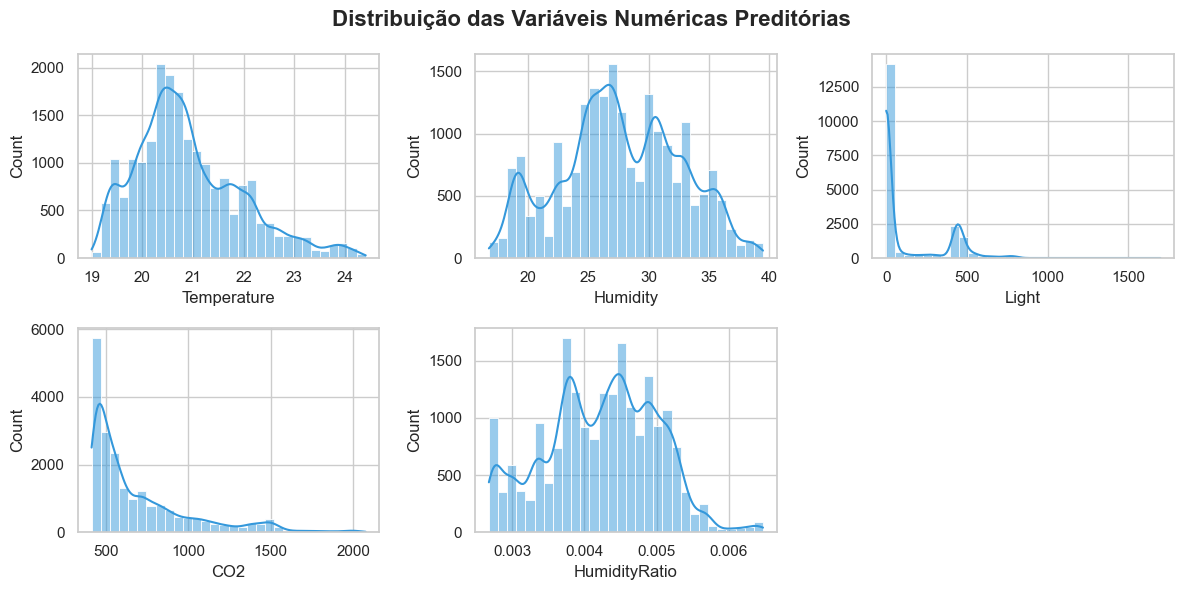

In [33]:
# Histograma das variáveis numéricas preditorias 

variaveis_preditorias = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
axes = axes.flatten()
for i, coluna in  enumerate(variaveis_preditorias):
    sns.histplot(data=df, x=coluna, bins=30, kde=True, ax=axes[i] , color='#3498db')
axes[5].axis('off')
plt.suptitle('Distribuição das Variáveis Numéricas Preditórias', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
### Análise das Variáveis Preditivas (Histogramas)

A visualização das distribuições das variáveis preditivas é essencial para entender o comportamento dos dados e como os ambientes do complexo industrial se comportam.

*(Nota: O eixo "Count" representa o número de leituras feitas ao longo do período do nosso dataset, conforme discutido no início do notebook).*

Com base nos histogramas gerados, observamos os seguintes padrões:

*   **Temperature:** Apresenta uma distribuição em formato de sino (aproximadamente normal). Isso indica que a temperatura é mantida quase sempre em torno de 20,5 °C, mostrando que não há grandes variações térmicas dentro do complexo industrial (devido à atuação do HVAC).
*   **Light:** Comporta-se de forma oposta à temperatura, com um padrão quase **binário**. Há um pico massivo no valor 0 (ambiente escuro na maior parte do tempo, representado por cerca de 16 mil leituras) e um segundo pico em valores mais altos, como 500 Lux (luz ligada em menor tempo, representada pelas próximas 2 mil leituras).
*   **CO₂:** Apresenta um comportamento mais complexo, mas, assim como a luz, exibe forte **assimetria à direita**. Vemos um pico à esquerda (valores baixos de ppm em muitas leituras) e picos menores, porém mais altos em ppm. Isso indica a presença variável de pessoas no ambiente em diferentes momentos do dia.
*   **Humidity e HumidityRatio:** Apresentam um padrão muito parecido com uma distribuição normal, o que é produto de ser um ambiente fechado e com climatização controlada.

**Conclusão para a Modelagem:**
O que podemos concluir é que a **Light** e o **CO₂** são as variáveis que apresentam um padrão visual mais distinto (assimétrico e binário). Portanto, elas serão as mais significativas e terão grande peso durante o treinamento e teste do nosso modelo de Machine Learning (Árvore de Decisão e KNN).

In [ ]:
# Analises da coluna alvo (Occupancy)
df ['Occupancy'].value_counts(normalize=True).round(2) * 100

Occupancy
0    77.0
1    23.0
Name: proportion, dtype: float64

Text(0.5, 0, 'Sala desocupada (0) / Sala ocupada (1)')

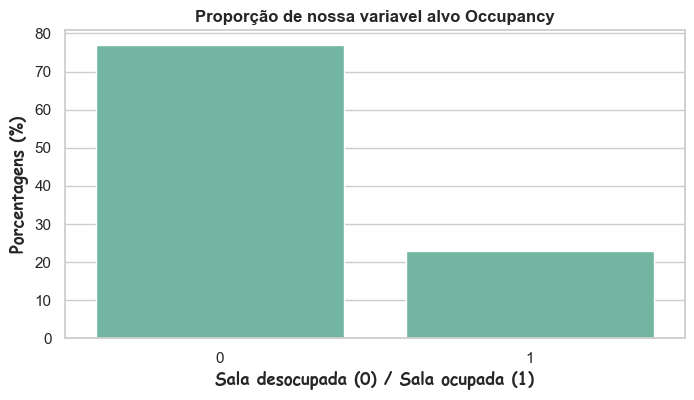

In [ ]:
# Gráfico de barras da proporção da variável alvo (Occupancy)
proporcoes = df ['Occupancy'].value_counts(normalize=True).round(2) * 100
plt.figure(figsize=(8,4))
sns.barplot(x=proporcoes.index,y= proporcoes.values)
plt.title ('Proporção de nossa variavel alvo Occupancy' , fontweight ='bold')
plt.ylabel('Porcentagens (%)', fontweight = 'semibold', font = 'cursive')
plt.xlabel('Sala desocupada (0) / Sala ocupada (1)', fontweight = 'semibold', font = 'cursive')

Text(0.5, 1.0, 'Mapa de Calor - Correlação de Pearson')

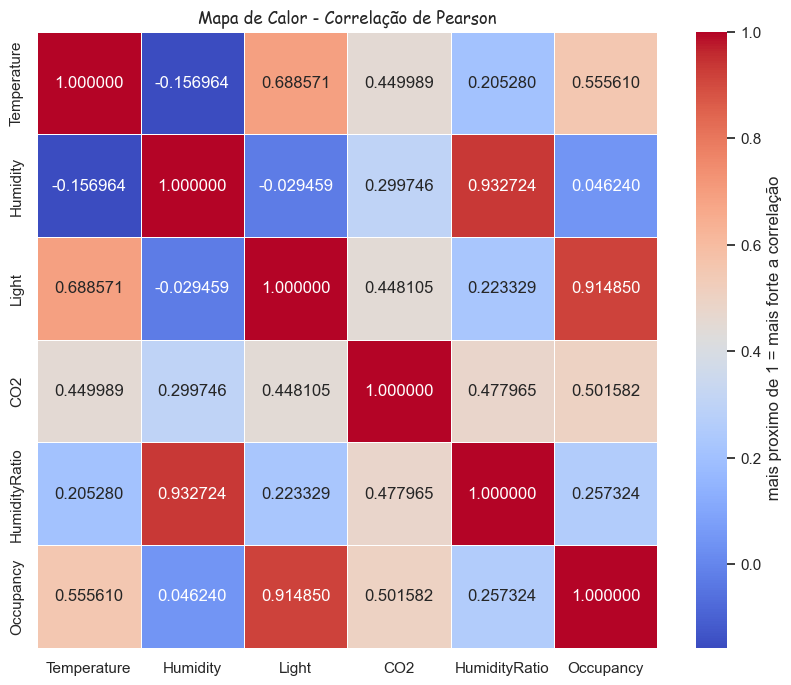

In [47]:
# Gráfico de mapa de calor com a correlação de Pearson entre as variáveis preditórias e a variável alvo (Occupancy)
matriz_correlacao = df.corr(method= 'pearson')
matriz_correlacao.drop(index=['date'], columns=['date'], inplace=True)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacao, annot= True, cmap= 'coolwarm', fmt='2f', linewidths= 0.5, cbar_kws={'label': ' mais proximo de 1 = mais forte a correlação'})
plt.title('Mapa de Calor - Correlação de Pearson', fontweight='bold', fontsize=16 , font = 'cursive')

### 🔥 Análise da Matriz de Correlação (Heatmap)

A análise do mapa de calor de Pearson permitiu tirar conclusões importantes sobre quais variáveis devemos priorizar no nosso modelo de Machine Learning:

*   **Light (A Campeã):** A luminosidade mantém o padrão observado nos histogramas, apresentando uma forte correlação com a nossa variável alvo (~0.91). Isso reforça a necessidade de utilizá-la como a principal variável preditiva no treinamento do modelo.
*   **CO₂ vs. Temperature (A Nuance Biológica):** Embora o `CO2` (~0.50) tenha apresentado uma correlação linear ligeiramente inferior à `Temperature` (~0.55), ele é **estatística e logicamente mais relevante** para o nosso objetivo. 
    *   O `CO2` é um medidor real e biológico de presença humana (as pessoas exalam esse gás).
    *   Já a `Temperature` tem sua correlação inflada porque o sistema HVAC (ar-condicionado) atua para mantê-la estável justamente quando há pessoas na sala. 
    
**Conclusão para a Modelagem:**
A `Temperature` é uma variável de contexto (influenciada pelo sistema), enquanto o `CO2` é o gatilho de ocupação. Portanto, a estratégia para as próximas fases (treinamento e teste) será priorizar a `Light` e o `CO2` como as variáveis complementares mais importantes para que a Árvore de Decisão e o KNN consigam prever a ocupação com alta precisão.